# Movie Review Sentiment Classifier

This notebook uses a PyTorch LSTM to classify SST-5 movie review excerpts as negative, neutral, or positive. Run the sections in order.

## 1. Download and check the dataset

Download the training, validation, and test files. Check the row counts and see how many examples each class has.


In [11]:
from pathlib import Path
from collections import Counter
from urllib.request import urlretrieve
from nltk import Tree
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42)
root = Path('/content/sst5')
root.mkdir(exist_ok=True)
base = 'https://raw.githubusercontent.com/stanfordnlp/sentiment-treebank/master/fiveclass'
labels = ['negative', 'neutral', 'positive']
label_map = {0: 0, 1: 0, 2: 1, 3: 2, 4: 2}
splits = {}

# The updated GitHub files can differ in size from the original release.
for split in ('train', 'dev', 'test'):
    path = root / f'{split}.txt'
    urlretrieve(f'{base}/{split}.txt', path)
    rows = []
    for line in path.read_text(encoding='utf-8').splitlines():
        if line.strip():
            tree = Tree.fromstring(line)
            rows.append((' '.join(tree.leaves()), label_map[int(tree.label())]))
    if set(y for _, y in rows) != set(range(3)):
        raise ValueError(f'{split} must contain all three sentiment classes')
    splits[split] = rows
    print(split, len(rows), dict(Counter(labels[y] for _, y in rows)))

train 8527 {'positive': 3608, 'neutral': 1606, 'negative': 3313}
dev 1095 {'positive': 444, 'neutral': 223, 'negative': 428}
test 2203 {'neutral': 385, 'positive': 908, 'negative': 910}


## 2. Prepare text for the LSTM

Build the vocabulary from the training split. Convert each excerpt into token IDs and pad or truncate it to a fixed length. This section also defines the model.


In [12]:
from nltk.tokenize import TreebankWordTokenizer

tokenizer = TreebankWordTokenizer()
max_length = 64
vocab = {'<PAD>': 0, '<UNK>': 1}

def tokenize(text):
    return tokenizer.tokenize(text.lower().replace('(', ' -lrb- ').replace(')', ' -rrb- '))

counts = Counter(token for text, _ in splits['train'] for token in tokenize(text))
for token, _ in counts.most_common(15_000):
    if token not in vocab:
        vocab[token] = len(vocab)

def encode(text):
    ids = [vocab.get(token, 1) for token in tokenize(text)[:max_length]] or [1]
    return ids + [0] * (max_length - len(ids))

def loader(split, shuffle=False):
    rows = splits[split]
    data = TensorDataset(torch.tensor([encode(text) for text, _ in rows]),
                         torch.tensor([y for _, y in rows]))
    return DataLoader(data, batch_size=128, shuffle=shuffle)

class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 64, padding_idx=0)
        self.lstm = nn.LSTM(64, 64, batch_first=True)
        self.output = nn.Linear(64, 3)

    def forward(self, ids):
        states, _ = self.lstm(self.embedding(ids))
        last = (ids != 0).sum(dim=1) - 1
        return self.output(states[torch.arange(ids.size(0), device=ids.device), last])

## 3. Train a TF-IDF baseline

Train a logistic regression model to see how a simpler approach performs on the validation set.


In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

train_text, train_labels = zip(*splits['train'])
dev_text, dev_labels = zip(*splits['dev'])
baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    LogisticRegression(max_iter=1000, class_weight='balanced'),
)
baseline.fit(train_text, train_labels)
dev_predictions = baseline.predict(dev_text)
print('Baseline validation accuracy:', accuracy_score(dev_labels, dev_predictions))
print('Baseline validation macro F1:', f1_score(dev_labels, dev_predictions, average='macro'))


Baseline validation accuracy: 0.5908675799086758
Baseline validation macro F1: 0.5348565232590938


## 4. Train and select the LSTM

Track validation accuracy and macro F1 each epoch. Keep the weights from the epoch with the best validation macro F1.


In [14]:
import copy

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
epochs = 8  # Change to 1 for a quick smoke test.
train_batches = loader('train', shuffle=True)
dev_batches = loader('dev')
model = SentimentLSTM(len(vocab)).to(device)
optimizer = torch.optim.Adam(model.parameters())
class_counts = Counter(y for _, y in splits['train'])
weights = torch.tensor([len(train_labels) / (3 * class_counts[i]) for i in range(3)],
                       dtype=torch.float32, device=device)
loss_fn = nn.CrossEntropyLoss(weight=weights)

@torch.inference_mode()
def predict_batches(network, batches, inference_device):
    network.eval()
    actual, predicted = [], []
    for ids, y in batches:
        actual.extend(y.tolist())
        predicted.extend(network(ids.to(inference_device)).argmax(dim=1).cpu().tolist())
    return actual, predicted

history = []
best_f1 = -1
for epoch in range(1, epochs + 1):
    model.train()
    total_loss = 0.0
    for ids, y in train_batches:
        ids, y = ids.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(ids), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    actual, predicted = predict_batches(model, dev_batches, device)
    score = f1_score(actual, predicted, average='macro')
    history.append({'epoch': epoch, 'train_batch_mean_loss': total_loss / len(train_batches),
                    'validation_accuracy': accuracy_score(actual, predicted),
                    'validation_macro_f1': score})
    print(history[-1])
    if score > best_f1:
        best_f1, best_epoch = score, epoch
        best_weights = copy.deepcopy(model.state_dict())

model.load_state_dict(best_weights)
print(f'Selected epoch {best_epoch} on {device} by validation macro F1.')


{'epoch': 1, 'train_batch_mean_loss': 1.0961070861389388, 'validation_accuracy': 0.4319634703196347, 'validation_macro_f1': 0.3493228092912524}
{'epoch': 2, 'train_batch_mean_loss': 1.061405480797611, 'validation_accuracy': 0.4894977168949772, 'validation_macro_f1': 0.4075452397501975}
{'epoch': 3, 'train_batch_mean_loss': 1.0004648779755207, 'validation_accuracy': 0.4986301369863014, 'validation_macro_f1': 0.44072415129573844}
{'epoch': 4, 'train_batch_mean_loss': 0.9132415794614536, 'validation_accuracy': 0.4940639269406393, 'validation_macro_f1': 0.4282908166572746}
{'epoch': 5, 'train_batch_mean_loss': 0.8217090421648168, 'validation_accuracy': 0.491324200913242, 'validation_macro_f1': 0.456251876255517}
{'epoch': 6, 'train_batch_mean_loss': 0.7183226026705841, 'validation_accuracy': 0.508675799086758, 'validation_macro_f1': 0.4830918848010997}
{'epoch': 7, 'train_batch_mean_loss': 0.6179527128810314, 'validation_accuracy': 0.536986301369863, 'validation_macro_f1': 0.48776289022683

## 5. Evaluate on the test set

Compare both models using accuracy, macro F1, and confusion matrices. Review a few LSTM mistakes to see where it struggles.


TF-IDF baseline {'accuracy': 0.616432137993645, 'macro_f1': 0.549561071545907, 'confusion_matrix': [[585, 197, 128], [160, 103, 122], [121, 117, 670]]}
              precision    recall  f1-score   support

    negative       0.68      0.64      0.66       910
     neutral       0.25      0.27      0.26       385
    positive       0.73      0.74      0.73       908

    accuracy                           0.62      2203
   macro avg       0.55      0.55      0.55      2203
weighted avg       0.62      0.62      0.62      2203



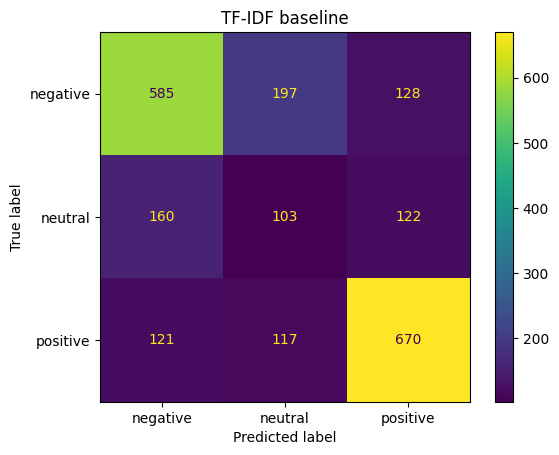

LSTM {'accuracy': 0.5333635950975942, 'macro_f1': 0.4878780431416682, 'confusion_matrix': [[601, 208, 101], [182, 116, 87], [242, 208, 458]]}
              precision    recall  f1-score   support

    negative       0.59      0.66      0.62       910
     neutral       0.22      0.30      0.25       385
    positive       0.71      0.50      0.59       908

    accuracy                           0.53      2203
   macro avg       0.50      0.49      0.49      2203
weighted avg       0.57      0.53      0.54      2203



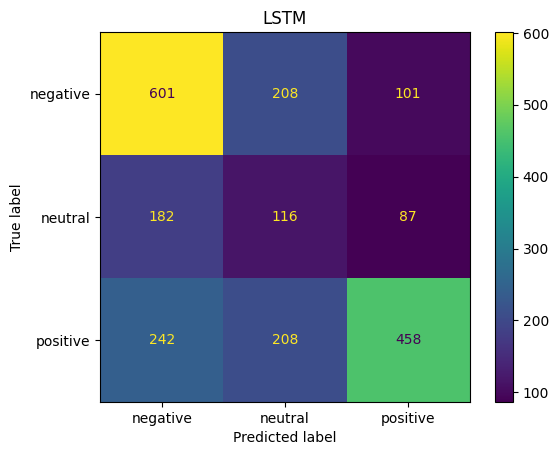

Example LSTM errors
Expected positive | Predicted negative | Emerges as something rare , an issue movie that 's so honest and keenly observed that it does n't feel like one .
Expected neutral | Predicted positive | The film provides some great insight into the neurotic mindset of all comics -- even those who have reached the absolute top of the game .
Expected positive | Predicted negative | Perhaps no picture ever made has more literally showed that the road to hell is paved with good intentions .
Expected positive | Predicted neutral | Steers turns in a snappy screenplay that curls at the edges ; it 's so clever you want to hate it .
Expected positive | Predicted negative | But he somehow pulls it off .


In [15]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_text, test_labels = zip(*splits['test'])
_, lstm_predictions = predict_batches(model, loader('test'), device)
test_metrics = {}

for name, predictions in [('TF-IDF baseline', baseline.predict(test_text)),
                          ('LSTM', lstm_predictions)]:
    matrix = confusion_matrix(test_labels, predictions, labels=range(3))
    test_metrics[name] = {
        'accuracy': float(accuracy_score(test_labels, predictions)),
        'macro_f1': float(f1_score(test_labels, predictions, average='macro')),
        'confusion_matrix': matrix.tolist(),
    }
    print(name, test_metrics[name])
    print(classification_report(test_labels, predictions, labels=range(3),
                                target_names=labels, zero_division=0))
    ConfusionMatrixDisplay(matrix, display_labels=labels).plot()
    plt.title(name)
    plt.show()

print('Example LSTM errors')
for (review, truth), prediction in [(row, pred) for row, pred in
                                    zip(splits['test'], lstm_predictions) if row[1] != pred][:5]:
    print(f'Expected {labels[truth]} | Predicted {labels[prediction]} | {review}')


## 6. Save and reload the model

Export the weights and preprocessing settings, then reload the checkpoint on CPU and predict the sentiment of a sample review.


In [16]:
checkpoint = Path('/content/sst5_lstm_v1.pt')
torch.save({
    'weights': model.cpu().state_dict(),
    'model_config': {'embedding_dim': 64, 'hidden_dim': 64, 'num_classes': 3},
    'dataset': base,
    'model_version': 'sst5_lstm_v1',
    'selected_epoch': best_epoch,
    'validation_macro_f1': float(best_f1),
    'test_metrics': test_metrics,
    'vocab': vocab,
    'max_length': max_length,
    'labels': labels,
    'tokenizer': 'lowercase_treebank_v1',
}, checkpoint)

saved = torch.load(checkpoint, map_location='cpu', weights_only=True)
vocab, max_length = saved['vocab'], saved['max_length']
restored = SentimentLSTM(len(vocab))
restored.load_state_dict(saved['weights'])
restored.eval()
with torch.inference_mode():
    probs = restored(torch.tensor([encode('The acting was wonderful.')])).softmax(dim=1)[0]
print('Reloaded on CPU:', saved['labels'][probs.argmax().item()])
print('Checkpoint:', checkpoint)

Reloaded on CPU: positive
Checkpoint: /content/sst5_lstm_v1.pt


## 7. Back up the checkpoint (optional)

Enable the cell below to copy the checkpoint to Drive, or download it from the Colab Files panel. Keep this notebook with the checkpoint for the model and tokenizer code.


In [17]:
# Optional. Set to True to keep the checkpoint in Drive.
save_to_drive = False
if save_to_drive:
    from google.colab import drive
    import shutil

    drive.mount('/content/drive')
    destination = Path('/content/drive/MyDrive/movie-sentiment')
    destination.mkdir(exist_ok=True)
    print(shutil.copy2(checkpoint, destination))